In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
import math
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, ConcatDataset
from torchvision import datasets, transforms
from IPython.display import clear_output

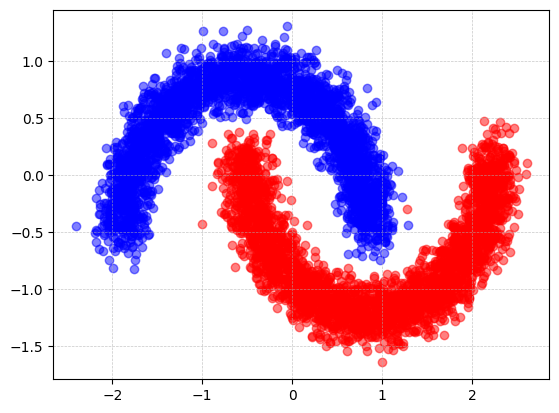

In [3]:
x, y = make_moons(n_samples=200000, noise=0.1)
x = (x - x.mean()) / x.std()

plt.scatter(x[:,0][y == 0][:3000], x[:,1][y == 0][:3000], alpha=0.5, color="blue")
plt.scatter(x[:,0][y == 1][:3000], x[:,1][y == 1][:3000], alpha=0.5, color="red")
plt.grid(
    True,
    linestyle='--',
    linewidth=0.5,
    alpha=0.7
)

In [4]:
X = torch.tensor(x, dtype=torch.float32)
diffusion_steps = 40
s = 0.008
timesteps = torch.tensor(range(0, diffusion_steps), dtype=torch.float32)
schedule = torch.cos((timesteps / diffusion_steps + s) / (1 + s) * torch.pi / 2)**2

baralphas = schedule / schedule[0]
betas = 1 - baralphas / torch.concatenate([baralphas[0:1], baralphas[0:-1]])
alphas = 1 - betas


In [5]:
def sample_timesteps(batch_size, diffusion_steps, power=2.0):
    u = torch.rand(batch_size, 1)
    t = (u ** power * diffusion_steps).long()
    return t

def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

rand_timesteps = sample_timesteps(X.shape[0], diffusion_steps)
noised1, _ = noise(X, rand_timesteps)

rand_timesteps = sample_timesteps(X.shape[0], diffusion_steps)
noised2, _ = noise(X, rand_timesteps)

phi_upper, phi_all = noised1[y == 1], noised2

In [6]:
n_all = phi_all.shape[0]
reg = 0.01

def rbf_features(X, centers, sigma=0.5):
    return torch.exp(-torch.cdist(X, centers)**2 / (2 * sigma**2))

centers = phi_upper[torch.randperm(len(phi_upper))[:100]]

Phi_denom = rbf_features(phi_all,   centers)
Phi_num   = rbf_features(phi_upper, centers)

H = (Phi_denom.T @ Phi_denom) / n_all + reg * torch.eye(100)
h = Phi_num.mean(dim=0).unsqueeze(1)

theta = torch.linalg.solve(H, h)

r = (Phi_denom @ theta).squeeze()

In [7]:
phi_all.shape

torch.Size([200000, 2])

In [8]:
Phi_denom.shape

torch.Size([200000, 100])

In [9]:
class DiffusionBlock(nn.Module):
    def __init__(self, nunits):
        super(DiffusionBlock, self).__init__()
        self.linear = nn.Linear(nunits, nunits)
        
    def forward(self, x: torch.Tensor):
        x = self.linear(x)
        x = nn.functional.relu(x)
        return x
        
class DiffusionModel(nn.Module):
    def __init__(self, nfeatures: int, nblocks: int = 2, nunits: int = 64):
        super(DiffusionModel, self).__init__()
        
        self.inblock = nn.Linear(nfeatures+1, nunits)
        self.midblocks = nn.ModuleList([DiffusionBlock(nunits) for _ in range(nblocks)])
        self.outblock = nn.Linear(nunits, nfeatures)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        val = torch.hstack([x, t])  # Add t to inputs
        val = self.inblock(val)
        for midblock in self.midblocks:
            val = midblock(val)
        val = self.outblock(val)
        return val

def rbf_kernel(X, Y, sigma=1.0):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    dist = XX - 2 * X @ Y.T + YY.T
    return torch.exp(-dist / (2 * sigma**2))

def mmd(X, Y, sigma=1.0):
    Kxx = rbf_kernel(X, X, sigma)
    Kyy = rbf_kernel(Y, Y, sigma)
    Kxy = rbf_kernel(X, Y, sigma)
    return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()

def pairwise_distances(X, Y):
    XX = (X**2).sum(dim=1, keepdim=True)
    YY = (Y**2).sum(dim=1, keepdim=True)
    return XX - 2 * X @ Y.T + YY.T

def knn_fraction_coverage(X, Y, k=1, threshold=0.1):
    dist2 = pairwise_distances(X, Y)
    knn_dist = dist2.topk(k, largest=False, dim=1).values.sqrt()
    covered = (knn_dist.mean(dim=1) <= threshold).float()
    return covered.mean()

def knn_fraction_coverage_both(X, Y, k=1, threshold=0.1):
    cov_xy = knn_fraction_coverage(X, Y, k, threshold)
    cov_yx = knn_fraction_coverage(Y, X, k, threshold)
    return cov_xy, cov_yx

In [10]:
def noise(Xbatch, t):
    eps = torch.randn(size=Xbatch.shape)
    noised = (baralphas[t] ** 0.5).repeat(1, Xbatch.shape[1]) * Xbatch + ((1 - baralphas[t]) ** 0.5).repeat(1, Xbatch.shape[1]) * eps
    return noised, eps

noiselevel = 20
noised, eps = noise(X, torch.full([len(X), 1], fill_value=noiselevel))
denoised = 1 / torch.sqrt(baralphas[noiselevel]) * (noised - torch.sqrt(1 - baralphas[noiselevel]) * eps)

model = DiffusionModel(nfeatures=2, nblocks=6)
device = "cpu"
model = model.to(device)

nepochs = 100
batch_size = 2048


loss_fn = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.01, total_iters=nepochs)

print(sum(p.numel() for p in model.parameters()))

25346


In [11]:
model.load_state_dict(torch.load('model.pt'))

<All keys matched successfully>

In [14]:
nfeatures, nsamples = 2, 5000
s = 3
xt_hist = []
xt = torch.randn(size=(nsamples, nfeatures)).to(device)
xt_hist.append(xt.cpu())

centers_gpu = centers.float().to(device)
theta_gpu = theta.float().to(device)
sigma = 0.5

for t in range(diffusion_steps-1, 0, -1):
    with torch.no_grad():
        predicted_noise = model(xt, torch.full([nsamples, 1], t).to(device))

    xt_grad = xt.detach().requires_grad_(True)

    dists = torch.cdist(xt_grad, centers_gpu) ** 2
    phi_xt = torch.exp(-dists / (2 * sigma ** 2))  # (nsamples, n_centers)

    ratio = phi_xt @ theta_gpu          # (nsamples, 1)
    log_r = torch.log(torch.clamp(ratio, min=1e-8))
    guide_score = torch.autograd.grad(log_r.sum(), xt_grad)[0]

    xt = 1 / (alphas[t] ** 0.5) * (xt - (1 - alphas[t]) / ((1 - baralphas[t]) ** 0.5) * predicted_noise)
    xt = xt + s * betas[t] * guide_score

    if t == int(diffusion_steps/4) or t == int(diffusion_steps/2) or t == int(3*diffusion_steps/4):
        xt_hist.append(xt.cpu())

    if t > 1:
        variance = betas[t]
        std = variance ** 0.5
        xt += std * torch.randn(size=(nsamples, nfeatures)).to(device)

xt_hist.append(xt.cpu())
xt = xt.cpu()

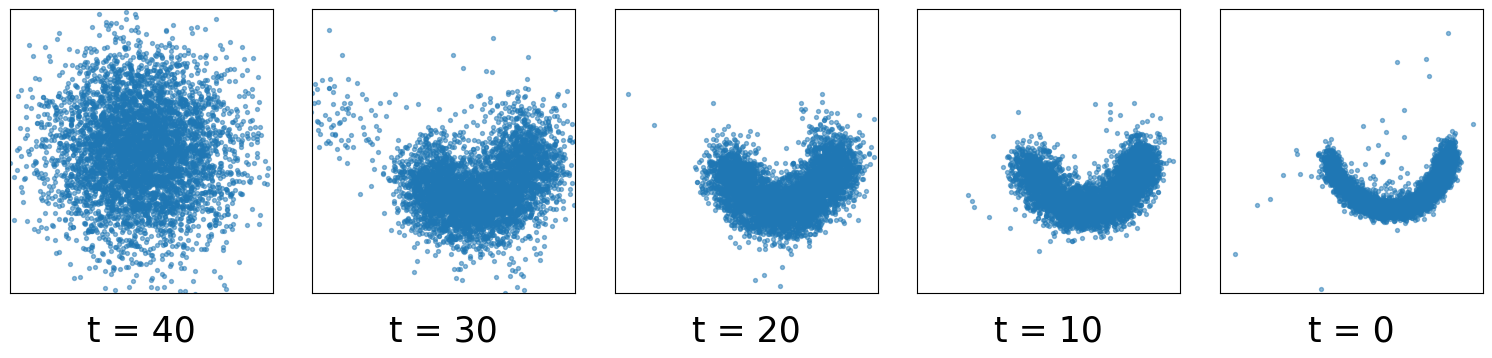

In [15]:
import matplotlib.pyplot as plt

n = len(xt_hist)

fig, axes = plt.subplots(1, n, figsize=(3.8*n, 4.5))

if n == 1:
    axes = [axes]

for i, (ax, img) in enumerate(zip(axes, xt_hist)):
    ax.scatter(img[:, 0], img[:, 1], s=8, alpha=0.5)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_title(
        f"t = {[0, int(diffusion_steps/4), 2*int(diffusion_steps/4), int(3*diffusion_steps/4), diffusion_steps][::-1][i]}",
        y=-0.2,
        fontsize=25
    )

plt.subplots_adjust(wspace=0.15, bottom=0.25)
plt.show()